# Poisson方程式はなぜ半導体・熱・流体・重力に現れるのか

## 概要

Poisson方程式が異なる分野に現れる理由を、勾配と発散から確認する。半導体の電位、定常温度、非圧縮流体の圧力、Newton重力を扱い、一次元差分法と二次元の圧力補正をPythonで計算する。

## 実行環境

Python 3.14.6、仮想環境・カーネル名は `wa-src(3.14.6)` である。NumPy、SciPy、Matplotlib、IPythonを使う。上から順に実行すると、図を `103_nb_files` にSVGで保存する。数値表示は有効数字3桁とする。

In [1]:
from pathlib import Path
from pprint import pprint
import platform

import numpy as np
import scipy
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats
from IPython.display import Latex, display

%matplotlib inline
# 保存はSVG、出力欄には未信頼のNotebookでも読めるPNGも埋め込む。
set_matplotlib_formats('svg', 'png')

print('実行環境: wa-src(3.14.6)')
print(f'Python: {platform.python_version()}')
print(f'OS: {platform.system()} / {platform.machine()}')
for module in (np, scipy, matplotlib):
    print(f'{module.__name__}: {module.__version__}')
assert platform.python_version() == '3.14.6', '指定のカーネルを選択する'

# Notebookの隣に保存する。リポジトリ直下からの実行にも対応する。
relative_dir = Path('rec/Interdisciplinarity/103')
notebook_dir = relative_dir if relative_dir.is_dir() else Path.cwd()
image_dir = notebook_dir / '103_nb_files'
image_dir.mkdir(exist_ok=True)


def sig3(value):
    """末尾のゼロも残して、有効数字3桁で表示する。"""
    return '0' if value == 0 else f'{float(value):#.3g}'


np.set_printoptions(formatter={'float_kind': sig3})
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'lines.linewidth': 1.60,
    'svg.fonttype': 'none',
})


def show_equation(source):
    # 重要式は \(...\) で指定し、表示用LaTeXでは $$...$$ に変換する。
    assert source.startswith(r'\(') and source.endswith(r'\)')
    display(Latex('$$' + source[2:-2] + '$$'))


def save_figure(fig, filename):
    """目盛も3桁に統一し、SVG保存とNotebook表示を行う。"""
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: sig3(value)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: sig3(value)))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.yaxis.set_minor_formatter(NullFormatter())
    fig.savefig(image_dir / filename, format='svg', bbox_inches='tight')
    plt.show()
    plt.close(fig)

実行環境: wa-src(3.14.6)
Python: 3.14.6
OS: Darwin / arm64
numpy: 2.5.4
scipy: 1.18.1
matplotlib: 3.11.2


## 1. 勾配と発散を組み合わせる

スカラー場$u$の勾配は変化の方向と大きさを表す。流束を$\mathbf{J}=-a\nabla u$とすると、外向き単位法線$\mathbf{n}$を持つ領域$V$で、源$s$との釣り合いは

$$
\int_{\partial V}\mathbf{J}\cdot\mathbf{n}\,dS
=\int_Vs\,dV
=\int_V\nabla\cdot\mathbf{J}\,dV.
$$

任意の$V$で成り立つため、$\nabla\cdot\mathbf{J}=s$である。代入して

$$
-\nabla\cdot(a\nabla u)=s,
\qquad a=\text{一定}>0
\quad\Rightarrow\quad
\nabla^2u=-\frac{s}{a}=f.
$$

ここで$\nabla^2u=\partial_x^2u+\partial_y^2u+\partial_z^2u$である。$f=0$ならLaplace方程式になる。$a$が場所で変わる場合には$\nabla a\cdot\nabla u$も残り、単純な定数係数の形にはならない。

In [2]:
show_equation(r'\(\boxed{\nabla^2u=f}\qquad\mathbf{J}=-a\nabla u\)')

<IPython.core.display.Latex object>

## 2. 半導体：電荷から電位へ

静電近似では、電束密度$\mathbf{D}$、電場$\mathbf{E}$、電位$\phi$は次を満たす。

$$
\begin{aligned}
\nabla\cdot\mathbf{D}&=\rho_e,
&\mathbf{D}&=\varepsilon\mathbf{E},
&\mathbf{E}&=-\nabla\phi,\\
-\nabla\cdot(\varepsilon\nabla\phi)&=\rho_e
&\Rightarrow\quad\nabla^2\phi&=-\rho_e/\varepsilon
\quad(\varepsilon=\text{一定}).
\end{aligned}
$$

電荷密度は$\rho_e=e(p_h-n+N_D^+-N_A^-)$である。$e>0$は電気素量、$p_h,n$は正孔・電子密度、$N_D^+,N_A^-$はイオン化したドナー・アクセプター密度を表す。実際にはキャリア密度も電位に依存するため、輸送方程式などと連立する。[Dhar, Semiconductor Device Equations](https://www.iue.tuwien.ac.at/phd/dhar/node21.html)

## 3. 熱：蓄積がなくなった温度場

体積熱容量$C$、発熱密度$Q$、熱伝導率$\kappa$を使う。移流を含まない熱収支とFourier則から

$$
\begin{aligned}
C\partial_tT+\nabla\cdot\mathbf{q}&=Q,
&\mathbf{q}&=-\kappa\nabla T,\\
C\partial_tT-\nabla\cdot(\kappa\nabla T)&=Q,\\
\partial_tT=0,\quad\kappa=\text{一定}
&\Rightarrow-\kappa\nabla^2T=Q
\Rightarrow\nabla^2T=-Q/\kappa.
\end{aligned}
$$

定常状態では発熱と境界からの放熱が釣り合う。時間変化が残る場合は熱方程式を解く。[MIT 18.336, Lecture 10](https://math.mit.edu/~stevenj/18.336/)

## 4. 流体：圧力で非圧縮条件を満たす

密度$\rho_f$が一定の非圧縮流体では$\nabla\cdot\mathbf{v}=0$である。圧力以外の項で予測速度$\mathbf{v}^*$を計算し、時間刻み$\Delta t$で補正すると

$$
\begin{aligned}
\mathbf{v}^{n+1}&=\mathbf{v}^*-\frac{\Delta t}{\rho_f}\nabla p,\\
0=\nabla\cdot\mathbf{v}^{n+1}
&=\nabla\cdot\mathbf{v}^*-\frac{\Delta t}{\rho_f}\nabla^2p,\\
\nabla^2p&=\frac{\rho_f}{\Delta t}\nabla\cdot\mathbf{v}^*.
\end{aligned}
$$

これは射影法の圧力方程式である。定常状態に限らず、各時刻に速度の発散を取り除くために解く。数値的にも発散・勾配とPoisson演算子を整合させる必要がある。[Domino, 2006](https://web.stanford.edu/group/ctr/ctrsp06/domino.pdf)

## 5. 重力：符号の違い

Newton重力では、質量密度$\rho_m$、重力加速度$\mathbf{g}$、ポテンシャル$\Phi$の関係は

$$
\nabla\cdot\mathbf{g}=-4\pi G\rho_m,
\qquad\mathbf{g}=-\nabla\Phi
\quad\Rightarrow\quad
-\nabla^2\Phi=-4\pi G\rho_m
\quad\Rightarrow\quad
\nabla^2\Phi=4\pi G\rho_m.
$$

正の質量に向かう場なので、正の電荷の場合と符号が逆になる。一般相対論そのものの方程式ではない。[Tong, The Poisson and Laplace Equations](https://damtp.cam.ac.uk/user/tong/vc/vc5.pdf)

## 6. 同じ差分行列で計算する

区間$0\le x\le1$を$N$等分し、$h=1/N$とする。Taylor展開を足し合わせると

$$
\begin{aligned}
u(x_i\pm h)&=u_i\pm hu'_i+\frac{h^2}{2}u''_i
\pm\frac{h^3}{6}u^{(3)}_i+O(h^4),\\
u_{i-1}-2u_i+u_{i+1}&=h^2u''_i+O(h^4),\\
-u_{i-1}+2u_i-u_{i+1}&\approx-h^2f_i.
\end{aligned}
$$

内点では対角成分が$2$、隣接成分が$-1$の行列$\mathbf{A}$になる。境界値$u(0)=a,u(1)=b$は右辺の先頭と末尾に加える。最後は$\mathbf{A}\mathbf{u}=\mathbf{b}$を解くだけである。

In [3]:
def solve_poisson_1d(source, intervals=100, left=0, right=0):
    """u'' = source(x) を両端のDirichlet境界条件で解く。"""
    x = np.linspace(0, 1, intervals + 1)
    h = 1 / intervals
    size = intervals - 1
    matrix = diags(
        [-np.ones(size - 1), 2 * np.ones(size), -np.ones(size - 1)],
        offsets=[-1, 0, 1],
        format='csc',
    )
    rhs = -h**2 * np.asarray(source(x[1:-1]), dtype=float)
    rhs[0] += left
    rhs[-1] += right
    u = np.empty_like(x)
    u[0], u[-1] = left, right
    u[1:-1] = spsolve(matrix, rhs)
    return x, u


# 内点が3個の場合の行列。数式はdisplayで出力する。
show_equation(
    r'\(\underbrace{\begin{bmatrix}2&-1&0\\-1&2&-1\\0&-1&2\end{bmatrix}}_{\mathbf{A}}'
    r'\underbrace{\begin{bmatrix}u_1\\u_2\\u_3\end{bmatrix}}_{\mathbf{u}}'
    r'=\underbrace{\begin{bmatrix}-h^2f_1+a\\-h^2f_2\\-h^2f_3+b\end{bmatrix}}_{\mathbf{b}}\)'
)

<IPython.core.display.Latex object>

### 電位・温度・重力の比較

以下は無次元の平板モデルである。半導体では固定した一様な正電荷、熱では一様発熱、重力では面内一様な質量を仮定する。係数と源の大きさを$1$に揃え、両端を$u=0$とする。温度は基準温度からの差である。重力の基準は平板の両端であり、孤立天体の無限遠条件ではない。

一定の右辺$f=c$なら、積分と境界条件から

$$
\begin{aligned}
u''=c&\Rightarrow u'=cx+C_1
\Rightarrow u=\frac{c}{2}x^2+C_1x+C_2,\\
u(0)=a&\Rightarrow C_2=a,\\
u(1)=b&\Rightarrow C_1=b-a-\frac{c}{2},\\
u(x)&=a+(b-a)x+\frac{c}{2}x(x-1).
\end{aligned}
$$

電位・温度では$c=-1$、重力では$c=1$である。電場と熱流束は中央から外向き、重力は中央へ向く。私は式だけより、勾配も並べた方が符号を確認しやすい。

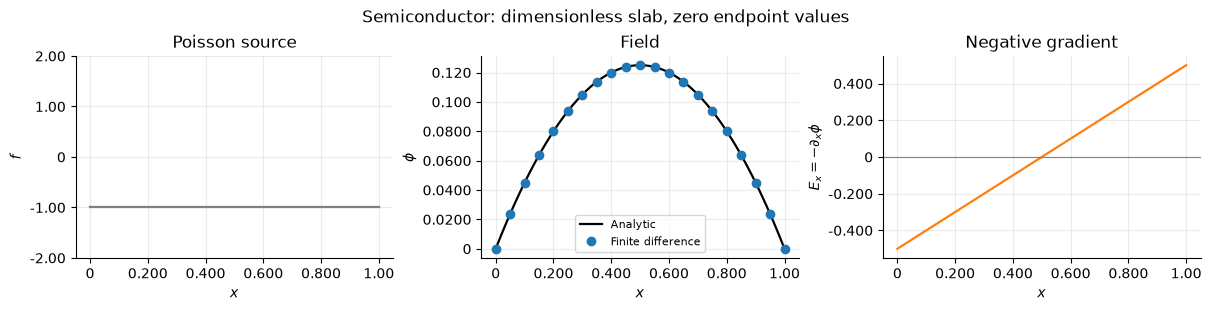

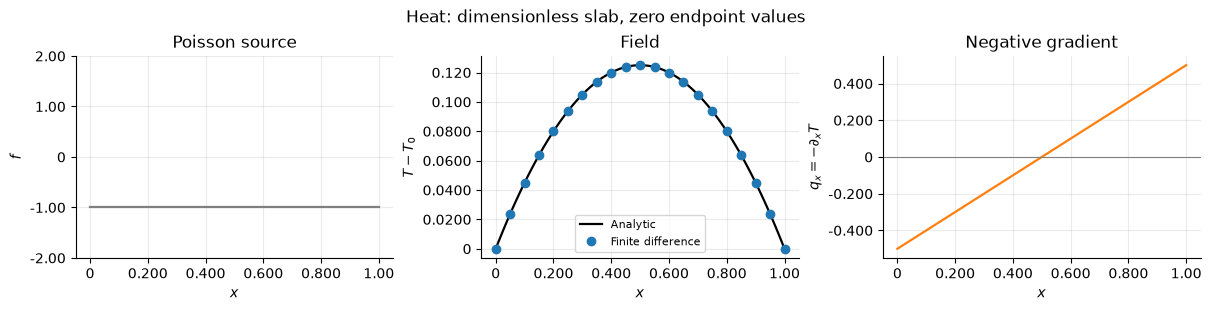

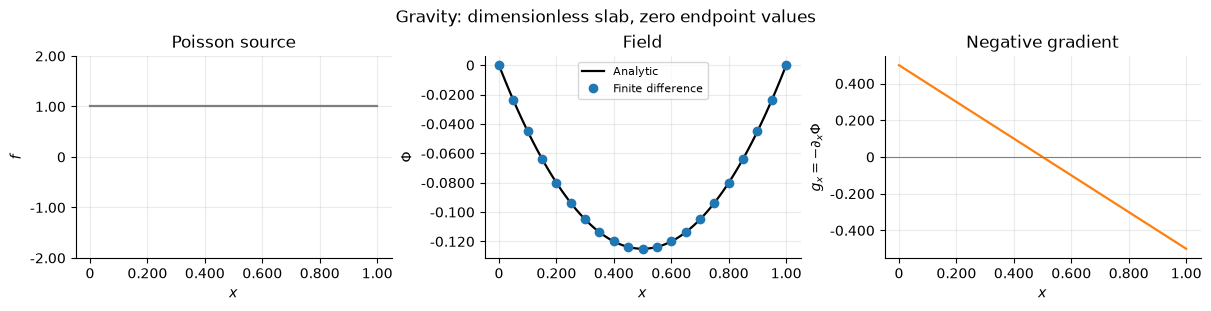

{'Semiconductor': {'max_solution_error': '1.05e-15',
                   'max_equation_residual': '4.45e-13'},
 'Heat': {'max_solution_error': '1.05e-15',
          'max_equation_residual': '4.45e-13'},
 'Gravity': {'max_solution_error': '1.05e-15',
             'max_equation_residual': '4.45e-13'}}


In [4]:
cases = [
    ('Semiconductor', -1, r'$\phi$', r'$E_x=-\partial_x\phi$', '01_semiconductor.svg'),
    ('Heat', -1, r'$T-T_0$', r'$q_x=-\partial_xT$', '02_heat.svg'),
    ('Gravity', 1, r'$\Phi$', r'$g_x=-\partial_x\Phi$', '03_gravity.svg'),
]
checks = {}

for title, c, field_label, flux_label, filename in cases:
    x, u = solve_poisson_1d(lambda z: np.full_like(z, c))
    exact = c * x * (x - 1) / 2
    flux = -np.gradient(u, x, edge_order=2)
    exact_flux = -c * (x - 1 / 2)
    residual = np.diff(u, n=2) / (x[1] - x[0])**2 - c
    checks[title] = {
        'max_solution_error': sig3(np.max(np.abs(u - exact))),
        'max_equation_residual': sig3(np.max(np.abs(residual))),
    }
    np.testing.assert_allclose(u, exact, atol=1.00e-12)
    np.testing.assert_allclose(flux, exact_flux, atol=1.00e-12)

    fig, axes = plt.subplots(1, 3, figsize=(12, 3), layout='constrained')
    fig.suptitle(f'{title}: dimensionless slab, zero endpoint values')
    axes[0].plot(x, np.full_like(x, c), color='tab:gray')
    axes[0].set(ylabel='$f$', title='Poisson source')
    axes[0].set_ylim(-2, 2)
    axes[1].plot(x, exact, color='black', label='Analytic')
    axes[1].plot(x[::5], u[::5], 'o', color='tab:blue', label='Finite difference')
    axes[1].set(ylabel=field_label, title='Field')
    axes[1].legend(fontsize=8)
    axes[2].plot(x, flux, color='tab:orange')
    axes[2].axhline(0, color='gray', linewidth=0.800)
    axes[2].set(ylabel=flux_label, title='Negative gradient')
    for ax in axes:
        ax.set_xlabel('$x$')
        ax.grid(alpha=0.250)
    save_figure(fig, filename)

pprint(checks, sort_dicts=False)

### 境界条件と誤差

同じ$f$でも境界値を変えると解は変わる。Dirichlet条件は値、Neumann条件は法線微分を指定する。全境界がNeumann条件の場合、$\int_V f\,dV=\int_{\partial V}\partial_nu\,dS$が必要で、解の定数分も別途固定する。

先の二次関数では差分が厳密なので、収束確認には$u=\sin(\pi x)$、$f=-\pi^2\sin(\pi x)$を使う。格子幅を半分にしたとき、最大誤差$E_h$が約$1/4$になることを確認する。

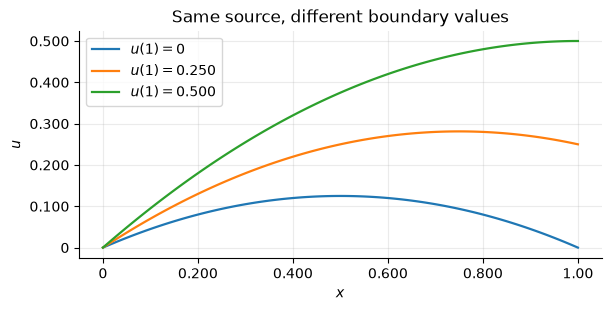

{'intervals': [16, 32, 64, 128],
 'max_errors': ['0.00322', '0.000804', '0.000201', '5.02e-05'],
 'observed_orders': ['2.00', '2.00', '2.00']}


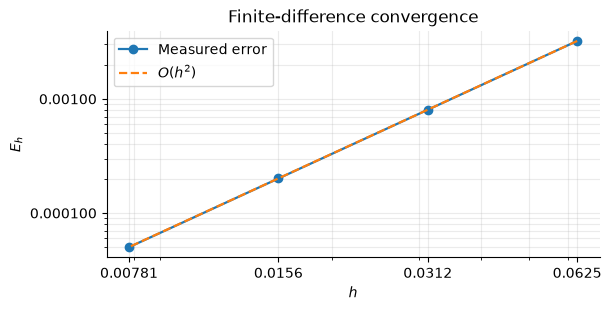

In [5]:
# 右端の値だけを変える。右辺と左端の値は共通である。
fig, ax = plt.subplots(figsize=(6, 3), layout='constrained')
for right in (0, 1 / 4, 1 / 2):
    x, u = solve_poisson_1d(lambda z: -np.ones_like(z), right=right)
    exact = right * x + x * (1 - x) / 2
    np.testing.assert_allclose(u, exact, atol=1.00e-12)
    ax.plot(x, u, label=f'$u(1)={sig3(right)}$')
ax.set(xlabel='$x$', ylabel='$u$', title='Same source, different boundary values')
ax.legend()
ax.grid(alpha=0.250)
save_figure(fig, '04_boundary_conditions.svg')

# 二次関数とは別の解析解で、二次精度を確認する。
counts = np.array([16, 32, 64, 128])
errors = []
for intervals in counts:
    x, u = solve_poisson_1d(
        lambda z: -np.pi**2 * np.sin(np.pi * z), intervals=int(intervals)
    )
    errors.append(np.max(np.abs(u - np.sin(np.pi * x))))
errors = np.asarray(errors)
orders = np.log2(errors[:-1] / errors[1:])
pprint({
    'intervals': counts.tolist(),
    'max_errors': [sig3(value) for value in errors],
    'observed_orders': [sig3(value) for value in orders],
}, sort_dicts=False)
assert np.all(np.abs(orders - 2) < 0.0100)

fig, ax = plt.subplots(figsize=(6, 3), layout='constrained')
h_values = 1 / counts
ax.loglog(h_values, errors, 'o-', label='Measured error')
ax.loglog(h_values, errors[0] * (h_values / h_values[0])**2, '--', label='$O(h^2)$')
ax.set(xlabel='$h$', ylabel='$E_h$', title='Finite-difference convergence')
ax.set_xticks(h_values)
ax.legend()
ax.grid(which='both', alpha=0.250)
save_figure(fig, '05_convergence.svg')

## 7. 二次元の圧力補正

周期領域$[0,2\pi)^2$で、$\psi=\Delta t\,p/\rho_f$と置く。解く式は$\nabla^2\psi=f=\nabla\cdot\mathbf{v}^*$である。Fourier変換では

$$
\nabla^2e^{i\mathbf{k}\cdot\mathbf{x}}
=-|\mathbf{k}|^2e^{i\mathbf{k}\cdot\mathbf{x}}
\Rightarrow-|\mathbf{k}|^2\widehat\psi=\widehat f
\Rightarrow\widehat\psi=-\widehat f/|\mathbf{k}|^2.
$$

周期条件では$f$の平均が$0$でなければ解けない。ゼロ波数は割り算せず、$\widehat\psi(\mathbf{0})=0$として平均を固定する。例を

$$
\mathbf{v}^*=\begin{bmatrix}\sin x+\sin y\\\cos x+\sin y\end{bmatrix}
\Rightarrow f=\cos x+\cos y
\Rightarrow\psi=-\cos x-\cos y
\Rightarrow\mathbf{v}=\mathbf{v}^*-\nabla\psi
=\begin{bmatrix}\sin y\\\cos x\end{bmatrix}
$$

と選ぶ。補正後の発散は解析的に$0$である。以下は射影の一回分であり、流体の時間発展全体は計算しない。

In [6]:
# 奇数個の周期格子を使い、Nyquist波数の扱いを避ける。
size = 63
length = 2 * np.pi
grid = np.arange(size) * length / size
X, Y = np.meshgrid(grid, grid, indexing='xy')
wave = 2 * np.pi * np.fft.fftfreq(size, d=length / size)
KX, KY = np.meshgrid(wave, wave, indexing='xy')
wave_squared = KX**2 + KY**2

vx_star = np.sin(X) + np.sin(Y)
vy_star = np.cos(X) + np.sin(Y)
vx_hat = np.fft.fft2(vx_star)
vy_hat = np.fft.fft2(vy_star)

# 発散、Poisson方程式、勾配を同じFourier微分で計算する。
source_hat = 1j * (KX * vx_hat + KY * vy_hat)
source = np.fft.ifft2(source_hat).real
assert abs(np.mean(source)) < 1.00e-12
psi_hat = np.zeros_like(source_hat)
nonzero = wave_squared > 0
psi_hat[nonzero] = -source_hat[nonzero] / wave_squared[nonzero]
psi = np.fft.ifft2(psi_hat).real
vx = vx_star - np.fft.ifft2(1j * KX * psi_hat).real
vy = vy_star - np.fft.ifft2(1j * KY * psi_hat).real
div_after = np.fft.ifft2(
    1j * (KX * np.fft.fft2(vx) + KY * np.fft.fft2(vy))
).real

psi_exact = -np.cos(X) - np.cos(Y)
np.testing.assert_allclose(psi, psi_exact, atol=1.00e-12)
np.testing.assert_allclose(vx, np.sin(Y), atol=1.00e-12)
np.testing.assert_allclose(vy, np.cos(X), atol=1.00e-12)
assert np.max(np.abs(div_after)) < 1.00e-12
pprint({
    'max_divergence_before': sig3(np.max(np.abs(source))),
    'max_divergence_after': sig3(np.max(np.abs(div_after))),
    'max_potential_error': sig3(np.max(np.abs(psi - psi_exact))),
}, sort_dicts=False)
show_equation(r'\(\nabla\cdot\mathbf{v}=\nabla\cdot\mathbf{v}^*-\nabla^2\psi=0\)')

{'max_divergence_before': '2.00',
 'max_divergence_after': '1.80e-14',
 'max_potential_error': '1.33e-15'}


<IPython.core.display.Latex object>

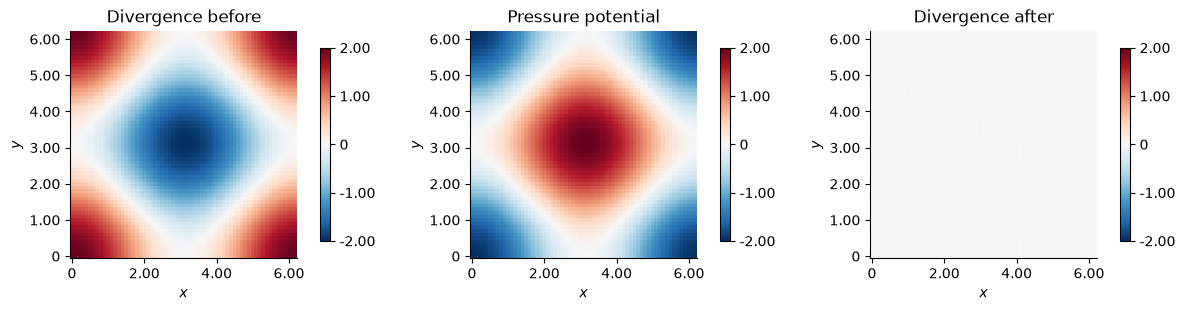

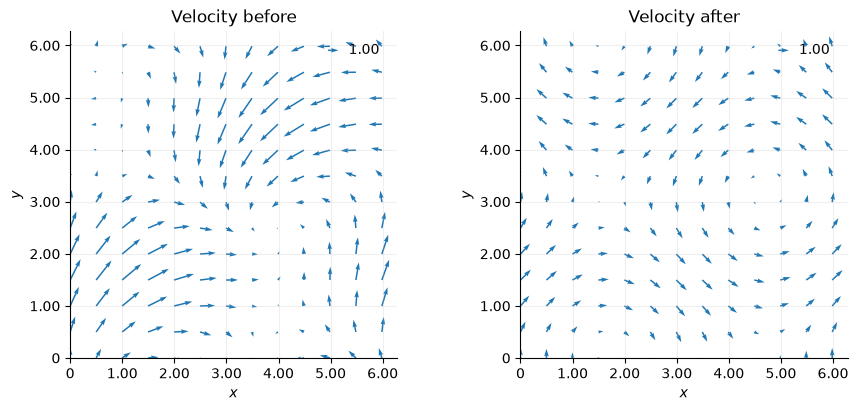

SVG保存先: 103_nb_files（7ファイル）


In [7]:
# 補正前後に同じ色範囲を使い、発散の減少を比較する。
fig, axes = plt.subplots(1, 3, figsize=(12, 3), layout='constrained')
fields = [source, psi, div_after]
titles = ['Divergence before', 'Pressure potential', 'Divergence after']
for ax, field, title in zip(axes, fields, titles):
    mesh = ax.pcolormesh(
        X, Y, field, cmap='RdBu_r', vmin=-2, vmax=2, shading='nearest'
    )
    ax.set(title=title, xlabel='$x$', ylabel='$y$', aspect='equal')
    fig.colorbar(mesh, ax=ax, ticks=[-2, -1, 0, 1, 2], shrink=0.850)
save_figure(fig, '06_pressure_projection.svg')

# 矢印の倍率も共通にして、残る回転成分を確認する。
fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout='constrained')
sample = (slice(None, None, 5), slice(None, None, 5))
for ax, ux, uy, title in zip(
    axes, [vx_star, vx], [vy_star, vy], ['Velocity before', 'Velocity after']
):
    arrows = ax.quiver(
        X[sample], Y[sample], ux[sample], uy[sample],
        angles='xy', scale_units='xy', scale=5, color='tab:blue',
    )
    ax.quiverkey(arrows, 0.820, 0.940, 1, '1.00', coordinates='axes', labelpos='E')
    ax.set(title=title, xlabel='$x$', ylabel='$y$', aspect='equal')
    ax.set_xlim(0, length)
    ax.set_ylim(0, length)
    ax.grid(alpha=0.200)
save_figure(fig, '07_velocity_projection.svg')

print('SVG保存先: 103_nb_files（7ファイル）')

## 結論

この記事では、Poisson方程式が勾配と発散、または非圧縮条件の組合せから現れることを確認した。

未知量と源の意味は分野ごとに異なるが、同じ数値解法を使える。符号、係数の一様性、境界条件を揃えることが比較の前提である。一次元では二次精度、二次元では圧力補正後の発散の減少を計算で確認した。